In [12]:
import numpy as np
import sympy as sp
from scipy.integrate import quad
import matplotlib.pyplot as plt
import math
import time
from scipy.linalg import hankel
import pandas as pd

In [13]:
def genelist(a, b, n):
    return np.linspace(a, b, int(n))

a = input('digite o extremo inferior: ');
b = input('digite o extremo superior: ');
eps = input('entre a precisao: ');
i =1;

f = @(x) exp(x)-x^2-3;
%f = inline(exp(x)-x^2-3)
if f(a) * f(b)>0
    disp('Sem raizes');
else
    fprintf('iteracao   valor   erro cometido\n');
    while (b-a)>eps
        x=(a+b)/2;
        if f(x)*f(a)<0
            b=x;
        else
            a=x;
        end
        erro = abs((b-a)/b);
        fprintf('%5d %19.5f %19.2e \n', i, x, erro);
        i=i+1;
    end
    fprintf('O valor da raiz eh %8.5f \n', x);
end

In [14]:
import numpy as np

def f(r, rs, M):
    return r + 2 * M * np.log(r / (2 * M) - 1) - rs

def findzero(f, range, tor):
    if not callable(f):
        raise TypeError("O argumento 'f' precisa ser uma função (ex: lambda x: ... ou def ...)")
    
    # Converte o intervalo para floats reais (equivalente ao // Re)
    range_arr = np.array(range, dtype=float)
    # fr = f /@ (range {1 + 10^-15, 1 - 10^-15}) // Re;
    deslocamento = np.array([1.0+1e-15, 1.0-1e-15])
    range_deslocado = range_arr * deslocamento
    fr = np.array([np.real(f(range_deslocado[0])), np.real(f(range_deslocado[1]))])

    # x0 = Mean@range // Re;
    x0 = np.real(np.mean(range_arr))

    # range1 = If[Re[f[x0]*fr[[1]]] > 0, {x0, range[[2]]}, {range[[1]], x0}] // Re;
    if np.real(f(x0) * fr[0]) > 0:
        range1 = np.array([x0, range_arr[1]])
    else:
        range1 = np.array([range_arr[0], x0])

    range1 = np.real(range1)
    # print(f"range1 = {range1}")
    
    # While[Abs@First@Differences@range1 > tor, ...
    while abs(range1[1] - range1[0])>tor:
        x0 = np.real(np.mean(range1))
        if np.real(f(x0) * fr[0])>0:
            range1 = [x0, range1[1]]
        else:
            range1 = [range1[0], x0]

        range1 = np.real(range1)
    return {'x': float(x0)}



In [15]:
# rstar = 25
# M = 1.0
# resultado = findzero(lambda r: f(r, rstar, M), [2 * M + 1e-15, 10000.0], 1e-6)
# print(f"Resultado do findzero: r é aproximadamente {resultado['x']:.6f}")

In [16]:
def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
    av, bv = pertubation_params
    rsmax = 2 * tmax
    rstarlist = genelist(rsv - rsmax/2.0, rsv + rsmax/2.0, numMax)
    
    def findrvalue(rs_target, M):
        #[2 * M + 1e-15, 10000.0] intervalo onde encontrar a raiz, 1e-6 é a tolerância, tendo relação dentro de ln, r/2m-1 >0, portanto r>2m
        return findzero(lambda r: f(r, rs_target, M), [2*M, 10000.0], 1e-12)['x']
    
    hr = float(np.diff(rstarlist[:2])[0])
    # print(f"rstarlist[0], rstarlist[1]: {rstarlist[0]}, {rstarlist[1]}"
    # )
    # print(f"rstarlist[1] - rstarlist[0]: {rstarlist[1] - rstarlist[0]}")
    # print(f"hr: {hr}")
    ht =0.5 * hr 

    inicio = time.time()
    rlist0 = np.array([findrvalue(rs, M) for rs in rstarlist], dtype = float)
    tempo_execucao  = time.time() - inicio
    print(f"Tempo de execução para encontrar rlist0: {tempo_execucao:.6f} segundos")

    rlist = rlist0

    def V_potencial(rlist, L, M):
        return (1.0 - 2* M/rlist) * (L*(L+1)/rlist**2 - 6 *M/rlist**3)

    Vv = V_potencial(rlist, L, M)

    ii = 1
    psi0 = np.zeros(len(rlist))
    psi1 = ht * np.exp(-((rstarlist - av)**2) / (2 * (bv**2)))
    length = int((numMax - 1) / 2)
    psi_collect = np.zeros(length)

    inicio_loop = time.time()
    while ii <= length:
        Vv = Vv[1:-1]
        psi2 = -(ht**2) * (
                    (psi0[1:-1] / (ht**2)) 
                    - (2 * psi1[1:-1] / (ht**2)) 
                    + (Vv * psi1[1:-1]) 
                    - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))
                )
        # if ii == 1:
        #     print(f"rstarlist[length - ii]: {rstarlist[length - ii]}")
        #     print(f"(ht**2): {ht**2}")
        #     print(f"psi0[length - ii]: {psi0[length - ii]}")
        #     print(f"psi1[length - ii]: {psi1[length - ii]}")
        #     print(f"Vv[length - ii]: {Vv[length - ii]}")
        #     print(f"(psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2): {(psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2)}")
        #     print(f"psi2[length - ii]: {psi2[length - ii - 1]}")
        #     print(f"psi2 = -(ht**2) * ((psi0[1:-1] / (ht**2)) - (2 * psi1[1:-1] / (ht**2)) + (Vv * psi1[1:-1]) - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))) --> {psi2[length - ii - 1]} = {-(ht**2)} * {((psi0[length - ii] / (ht**2)) - (2 * psi1[length - ii] / (ht**2)) + (Vv[length - ii] * psi1[length - ii]) - ((psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2))) }")
        psi0 = psi1[1:-1]
        psi1 = psi2

        psi_collect[ii-1] = psi1[length - ii]
        ii+=1

    tempo_execucao_loop  = time.time() - inicio_loop
    print(f"Tempo de execução do loop: {tempo_execucao_loop:.6f} segundos")
    return ht, psi_collect


In [17]:
def plotEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))
    plt.plot(t, psi, lw=2)

    t_max = t[-1]
    plt.xticks(np.arange(0, t_max + 1, 100))
    plt.xlabel("t")
    plt.ylabel(r"$\Psi$")
    plt.grid(True)
    plt.title(title)
    plt.show()


def plotLogEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

Tempo de execução para encontrar rlist0: 15.326329 segundos
Tempo de execução do loop: 0.812000 segundos


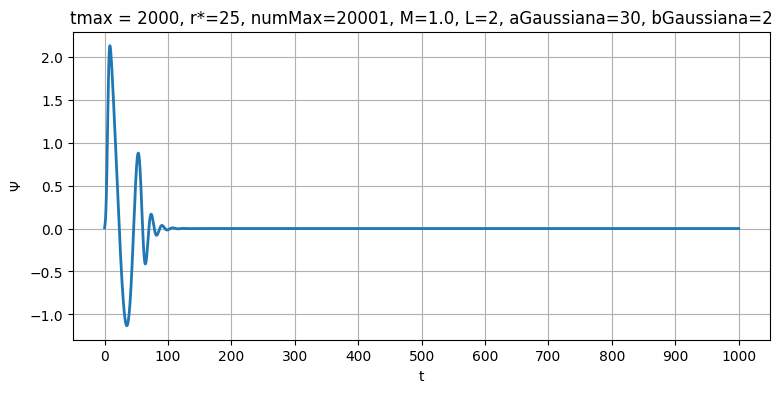

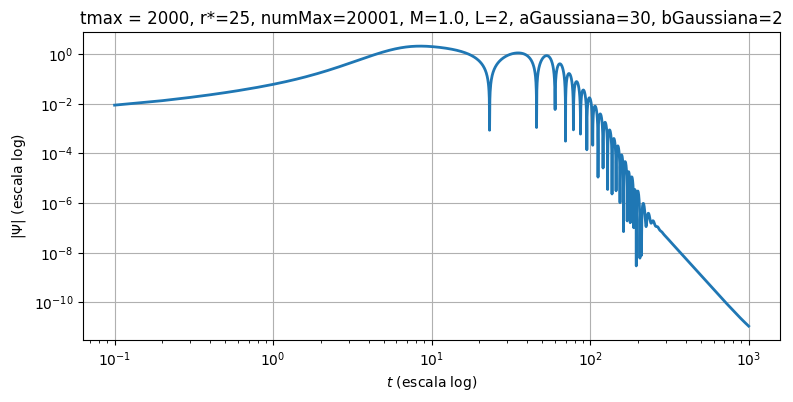

In [18]:
# def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
test1 = getEvo(2000, 25, 20001, 1.0, 2, (30, 2))
plotEvolution(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2, aGaussiana=30, bGaussiana=2"
)
plotLogEvolution(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2, aGaussiana=30, bGaussiana=2"
)

In [19]:
def plotLogEvolutionmod(test, title=""):

    ht, psi = test
    # print(f"len(psi): {len(psi)}")
    # print(f"ht: {ht}")

    t = ht * np.arange(3000, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi[2999:]),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

Default Return (full=False, cov=False)When you run the default configuration, it only returns the coefficients array (p).Shape: (deg + 1,) where deg is the polynomial degree you requested.Order: Highest degree term to lowest degree term (\(c_n, c_{n-1}, ..., c_0\)).Example: Fitting a line (y = mx + b) using deg=1 returns [m, b].

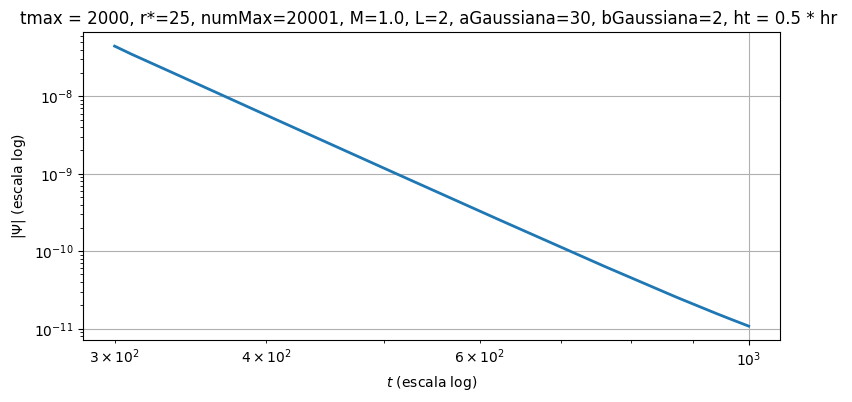

Inclinação = -6.994985
Intercepto = 22.930267


In [20]:
plotLogEvolutionmod(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2, aGaussiana=30, bGaussiana=2, ht = 0.5 * hr "
)


ht, psi = test1

# Tempo correspondente
t = ht * np.arange(1, len(psi) + 1)

# Intervalo desejado
inicio = 3000
fim = 9001      # o último índice (9000) é incluído

t_fit = t[inicio:fim]
psi_fit = np.abs(psi[inicio:fim])

# Evita log(0)
mask = psi_fit > 0

x = np.log(t_fit[mask])
y = np.log(psi_fit[mask])

# Ajuste linear
coef = np.polyfit(x, y, 1)

slope = coef[0]
intercept = coef[1]

print(f"Inclinação = {slope:.6f}")
print(f"Intercepto = {intercept:.6f}")

If a static I,-pole field is present outside the star, prior to the onset of collapse,
the field will fall off as t
'"'". If there is no field
initially outside the star, but an l-pole perturbation develops during the collapse process, it will
fall off as t^(2l+3) a.t la.rge time

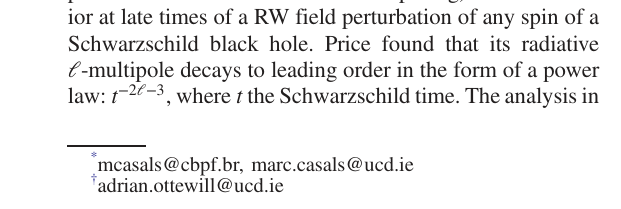

10.1103/PhysRevD.92.124055

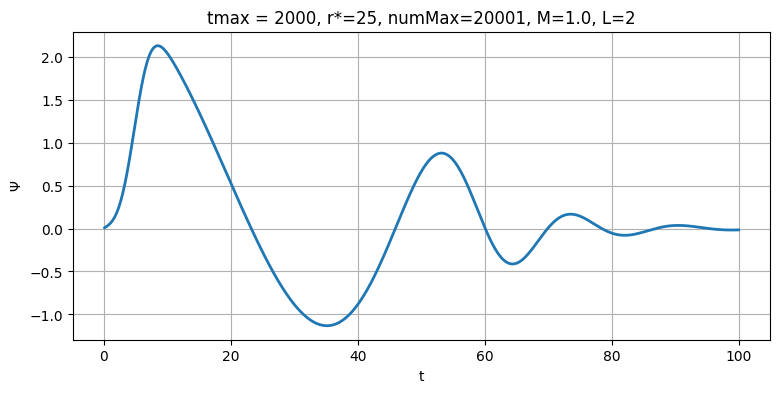

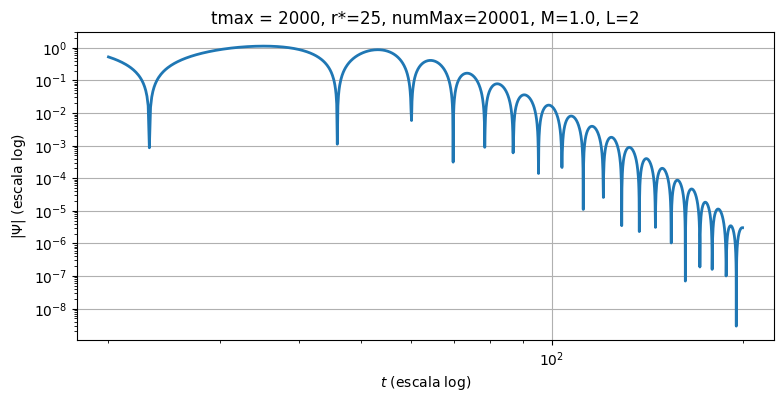

In [21]:
def plotLogEvolution20200(test, title=""):

    ht, psi = test
    # print(f"len(psi): {len(psi)}")
    # print(f"ht: {ht}")

    t = ht * np.arange(200, 2000)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi[199:1999]),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

def plotEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, 1001)

    plt.figure(figsize=(9,4))
    plt.plot(t, psi[0:1000], lw=2)

    
    plt.xlabel("t")
    plt.ylabel(r"$\Psi$")
    plt.grid(True)
    plt.title(title)
    plt.show()

plotEvolution(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2"
)

plotLogEvolution20200(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2"
)

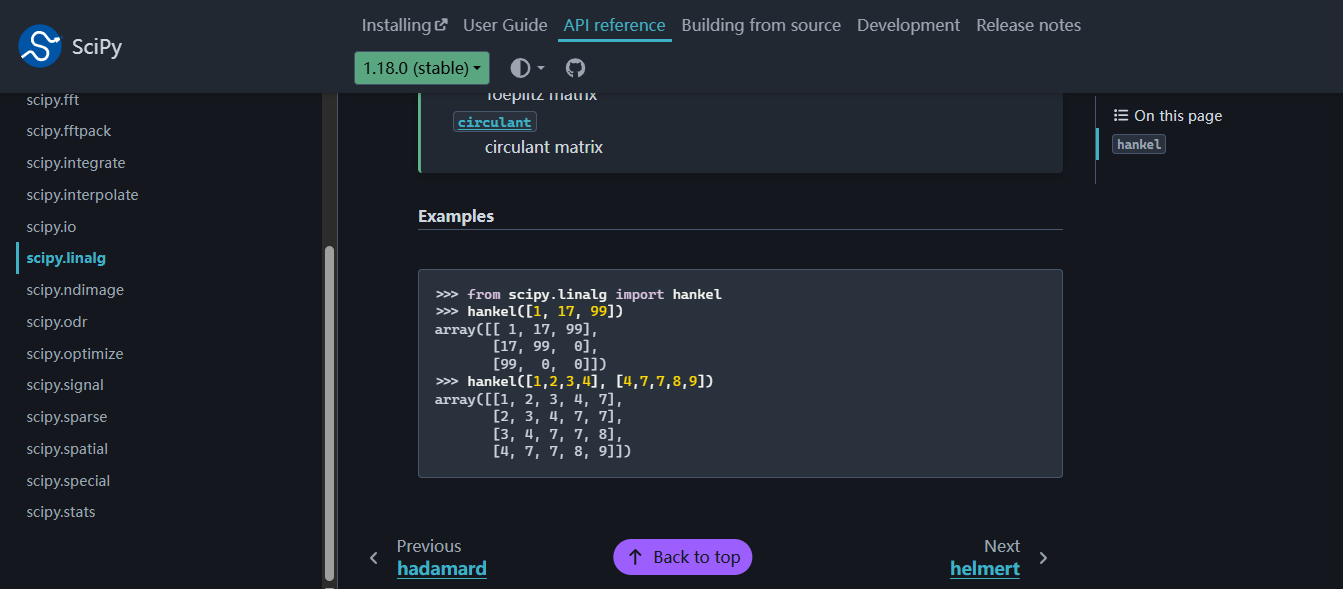

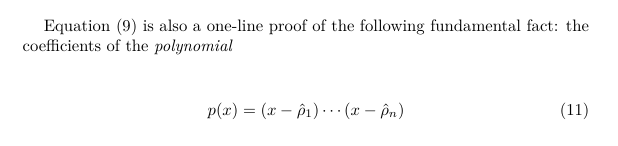

In [23]:

ht, psi = test1
range_array = psi[699:1199]
n = 6


num_colunas_total = n + 1  # 6 colunas para A + 1 coluna para o vetor b (total = 7)
num_linhas = len(range_array) - num_colunas_total + 1  # 500 - 7 + 1 = 494 linhas

# 3. Construir a Matriz de Hankel deslizante correta
# Primeira coluna: os primeiros num_linhas pontos
# Última linha: os últimos num_colunas_total pontos
c = range_array[:num_linhas]
r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #(494-1 : 494-1+7) = 493:500

matriz_hankel_completa = hankel(c, r)

# 4. Separar em Matriz A (300x6) e Vetor b (300x1)
# Se quiser limitar estritamente a 300 linhas:
# matriz_hankel_completa = matriz_hankel_completa[:300, :]

matriz_A = matriz_hankel_completa[:, :n]  # Colunas de Psi_0 até Psi_5 (300x6)
vetor_b = -matriz_hankel_completa[:, n]  # Coluna Psi_6 com sinal trocado (300x1)
# print(f"vetor_b: {vetor_b}")
print(f"matriz_a.shape: {matriz_A.shape}, vetor_b.shape: {vetor_b.shape}")

p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
    matriz_A, vetor_b, rcond=None
)

# 5. Salvar a Matriz A e o Vetor b em uma planilha do Excel
# Criamos um DataFrame do pandas organizando as colunas
# colunas_nomes = [f"Psi_k+{i}" for i in range(n)] + ["-Psi_k+6 (vetor_b)"]
# df_excel = pd.DataFrame(matriz_hankel_completa, columns=colunas_nomes)

# # Salva no arquivo Excel
# nome_arquivo = "matriz_hankel_prony.xlsx"
# df_excel.to_csv(nome_arquivo, index=False)

# print(f"Matriz de Hankel criada com sucesso! Formato: {matriz_hankel_completa.shape}")
# print(f"Arquivo salvo como: '{nome_arquivo}'")

#==========================================================================================
# 1. Agrupar todos os coeficientes em ordem DECRESCENTE de potência
# p_coef vem do lstsq: [p0, p1, p2, p3, p4, p5]
# O termo de maior grau p6 é igual a 1.0
coefs_polinomio = [1.0] + list(p_coef[::-1])

# 2. Encontrar os rhos (\hat{\rho}_j) calculando as raízes do polinômio
rhos = np.roots(coefs_polinomio)

# print("Os 'rhos' (raízes complexas) encontrados são:")
# print(rhos)

dt = ht

# Converter os 'rhos' para as frequências físicas omegas
omegas = 1j * np.log(rhos) / dt

# Exibir os resultados
for j, w in enumerate(omegas):
    print(
        f"Modo {j+1}: omega_R = {w.real:.8f} | omega_I = {-w.imag:.8f}"
    )

matriz_a.shape: (494, 6), vetor_b.shape: (494,)
Modo 1: omega_R = -0.37369874 | omega_I = 0.08905218
Modo 2: omega_R = 0.37369874 | omega_I = 0.08905218
Modo 3: omega_R = -0.00000000 | omega_I = 0.09462937
Modo 4: omega_R = -0.35184205 | omega_I = 0.26340026
Modo 5: omega_R = 0.35184205 | omega_I = 0.26340026
Modo 6: omega_R = -0.00000000 | omega_I = 0.57677145
